In [15]:
import pandas as pd
import numpy as np
import os
import sys
from matplotlib import pyplot as plt
import seaborn as sns

sys.path.append("../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../2_individual_assay_results")
from analyses_plot_utils import *

In [3]:
df = pd.read_csv('../3_outputs/Unified_1pct_Sahni_Rolland_Luck_Lacoste_Fragoza_260217_annotated.csv')
df

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_2160/637276674.py:1: DtypeWarning: Columns (9,22,23,163,165,195,216,217,218,220,221,223,225,231,246,247,249,250,252,253,255,256,259,269,270,273,277,278,279,280,290,291,301,302,303,314,315,318,319,540,542,544,546,548,550,560,562,564,566,568,570,576,578,584,588,590,592,596,614,616,618,624,626,630,632,642,644,646,654,656,708,710,712,714,718,724,728,760,762,764,774,776,796,884,936,938,940,942,944,972,974,978,980,982,986,998,999,1003,1005,1006,1007,1008,1009,1010,1012,1013,1016,1020,1021,1028,1030,1031,1033,1038,1039,1040,1044,1047,1048,1054,1056,1057,1058,1060,1062,1063) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../3_outputs/Unified_1pct_Sahni_Rolland_Luck_Lacoste_Fragoza_260217_annotated.csv')


,gene_variant,gene_symbol,aa_change,clinvar_clinical_significance_unified,clinvar_clinical_significance_source_unified,Edgotype_class,Edgotype_source,imaging_hit_unified,imaging_hit_unified_source,imaging_hit_discordant,...,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,am_pathogenicity
0,A2M_Cys972Tyr,A2M,Cys972Tyr,Benign,allele_col,NaN,NaN,False,Lacoste,NaN,...,70-90,<10,NaN,NaN,NaN,NaN,0.0,NaN,False,0.9488
1,A4GALT_Ala219Val,A4GALT,Ala219Val,VUS,allele_col,NaN,NaN,False,Lacoste,NaN,...,>90,<10,NaN,NaN,NaN,NaN,0.0,NaN,False,0.9612
2,A4GALT_Ala272Val,A4GALT,Ala272Val,NaN,NaN,NaN,NaN,False,Lacoste,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,A4GALT_Cys96Tyr,A4GALT,Cys96Tyr,Others,allele_col,NaN,NaN,False,Lacoste,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,False,0.9898
4,A4GALT_Met183Lys,A4GALT,Met183Lys,Others,allele_col,NaN,NaN,False,Lacoste,NaN,...,>90,<10,NaN,NaN,NaN,NaN,0.0,NaN,False,0.8767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6124,NECTIN1_Thr131Ala,NECTIN1,Thr131Ala,Others,allele_col,NaN,NaN,False,Lacoste,NaN,...,NaN,NaN,NaN,NaN,NaN,Rare genetic developmental defect during embry...,2.0,NaN,False,0.0604
6125,NHERF1_Arg153Gln,NHERF1,Arg153Gln,Conflicting,allele_col,NaN,NaN,False,Lacoste,NaN,...,70-90,10-90,612287,autosomal dominant,OMIM,NaN,0.0,"NEPHROLITHIASIS/OSTEOPOROSIS, HYPOPHOSPHATEMIC, 2",False,0.5088
6126,NHERF1_Leu110Val,NHERF1,Leu110Val,Conflicting,allele_col,NaN,NaN,False,Lacoste,NaN,...,50-70,10-90,612287,autosomal dominant,OMIM,NaN,0.0,"NEPHROLITHIASIS/OSTEOPOROSIS, HYPOPHOSPHATEMIC, 2",False,0.0954
6127,YARS1_Glu196Lys,YARS1,Glu196Lys,Pathogenic,allele_col,NaN,NaN,False,Lacoste,NaN,...,>90,10-90,608323;619418,multiple,OMIM,NaN,0.0,"CHARCOT-MARIE-TOOTH DISEASE, DOMINANT INTERMED...",False,0.7318


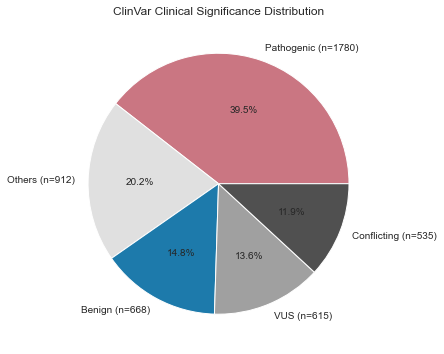

In [20]:
# Plot ClinVar Clinical Significance Distribution as a piechart using palette_dict colors

clinvar_counts = df['clinvar_clinical_significance_unified'].value_counts()
labels = [f'{cls} (n={count})' for cls, count in zip(clinvar_counts.index, clinvar_counts.values)]
plt.figure(figsize=(6, 6))
plt.pie(clinvar_counts, labels=labels, autopct='%1.1f%%', colors=[palette_dict['clinvar_clnsig_clean'][cls] for cls in clinvar_counts.index])
plt.title('ClinVar Clinical Significance Distribution')
plt.show()

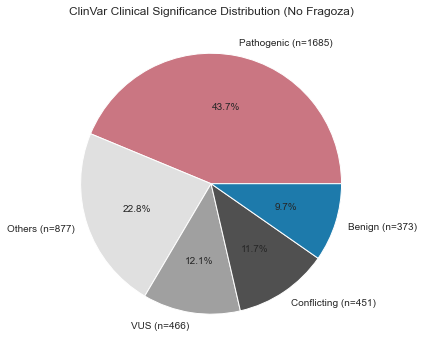

In [22]:
# Plot ClinVar Clinical Significance Distribution as a piechart using palette_dict colors without Fragoza variants

df_no_fragoza = df[~df['Source_Simple'].str.contains('Fragoza')]

clinvar_counts = df_no_fragoza['clinvar_clinical_significance_unified'].value_counts()
labels = [f'{cls} (n={count})' for cls, count in zip(clinvar_counts.index, clinvar_counts.values)]
plt.figure(figsize=(6, 6))
plt.pie(clinvar_counts, labels=labels, autopct='%1.1f%%', colors=[palette_dict['clinvar_clnsig_clean'][cls] for cls in clinvar_counts.index])
plt.title('ClinVar Clinical Significance Distribution (No Fragoza)')
plt.show()

Detected 6 sources: 1pct, Fragoza, Lacoste, Luck, Rolland, Sahni
Generating UpSet Plot (better for >3 sources)...


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles[

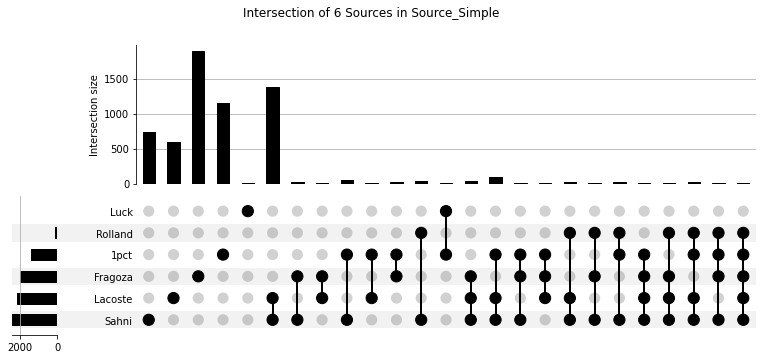

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2, venn3
from upsetplot import from_contents, plot as upset_plot

def visualize_variant_sources(df, column_name='Source_simple', delimiter=';'):
    """
    Automatically chooses between a Venn diagram and an UpSet plot 
    based on the number of unique sources found in the data.
    """
    # 1. Extract unique sources from the delimited strings
    # We drop NaNs and split by the delimiter (e.g., 'ClinVar;gnomAD')
    raw_entries = df[column_name].dropna().astype(str)
    unique_sources = set()
    for entry in raw_entries:
        unique_sources.update([s.strip() for s in entry.split(delimiter)])
    
    source_list = sorted(list(unique_sources))
    num_sources = len(source_list)
    
    print(f"Detected {num_sources} sources: {', '.join(source_list)}")

    if num_sources < 2:
        print("Error: Need at least 2 sources to show overlaps.")
        return

    # 2. Create a dictionary of sets (Source Name -> Set of Row Indices)
    # This is the standard input format for both Venn and UpSet logic
    content_dict = {
        src: set(df[df[column_name].str.contains(src, na=False, regex=False)].index)
        for src in source_list
    }

    # 3. Plotting Logic
    plt.figure(figsize=(12, 7))

    if num_sources <= 3:
        print("Generating Venn Diagram...")
        if num_sources == 2:
            venn2([content_dict[source_list[0]], content_dict[source_list[1]]], 
                  set_labels=source_list)
        else:
            venn3([content_dict[source_list[0]], content_dict[source_list[1]], content_dict[source_list[2]]], 
                  set_labels=source_list)
        plt.title(f"Overlap of {column_name}")
    
    else:
        print("Generating UpSet Plot (better for >3 sources)...")
        # upsetplot uses a specific data structure created via from_contents
        upset_data = from_contents(content_dict)
        upset_plot(upset_data, fig=plt.gcf(), orientation='horizontal')
        plt.suptitle(f"Intersection of {num_sources} Sources in {column_name}")

    plt.show()

visualize_variant_sources(df, column_name='Source_Simple', delimiter=';')

Detected 5 sources: 1pct, Lacoste, Luck, Rolland, Sahni
Generating UpSet Plot (better for >3 sources)...


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles[

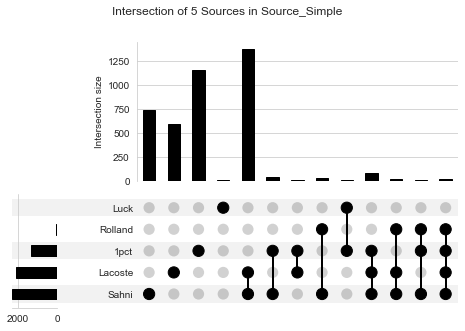

In [23]:
# Without Fragoza variants

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2, venn3
from upsetplot import from_contents, plot as upset_plot

def visualize_variant_sources(df, column_name='Source_simple', delimiter=';'):
    """
    Automatically chooses between a Venn diagram and an UpSet plot 
    based on the number of unique sources found in the data.
    """
    # 1. Extract unique sources from the delimited strings
    # We drop NaNs and split by the delimiter (e.g., 'ClinVar;gnomAD')
    raw_entries = df[column_name].dropna().astype(str)
    unique_sources = set()
    for entry in raw_entries:
        unique_sources.update([s.strip() for s in entry.split(delimiter)])
    
    source_list = sorted(list(unique_sources))
    num_sources = len(source_list)
    
    print(f"Detected {num_sources} sources: {', '.join(source_list)}")

    if num_sources < 2:
        print("Error: Need at least 2 sources to show overlaps.")
        return

    # 2. Create a dictionary of sets (Source Name -> Set of Row Indices)
    # This is the standard input format for both Venn and UpSet logic
    content_dict = {
        src: set(df[df[column_name].str.contains(src, na=False, regex=False)].index)
        for src in source_list
    }

    # 3. Plotting Logic
    plt.figure(figsize=(12, 7))

    if num_sources <= 3:
        print("Generating Venn Diagram...")
        if num_sources == 2:
            venn2([content_dict[source_list[0]], content_dict[source_list[1]]], 
                  set_labels=source_list)
        else:
            venn3([content_dict[source_list[0]], content_dict[source_list[1]], content_dict[source_list[2]]], 
                  set_labels=source_list)
        plt.title(f"Overlap of {column_name}")
    
    else:
        print("Generating UpSet Plot (better for >3 sources)...")
        # upsetplot uses a specific data structure created via from_contents
        upset_data = from_contents(content_dict)
        upset_plot(upset_data, fig=plt.gcf(), orientation='horizontal')
        plt.suptitle(f"Intersection of {num_sources} Sources in {column_name}")

    plt.show()

visualize_variant_sources(df_no_fragoza, column_name='Source_Simple', delimiter=';')

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu


# Filter for only Pathogenic and Benign variants for clear signal comparison
df_pb = df[df['clinvar_clinical_significance_unified'].isin(['Pathogenic', 'Benign'])].copy()

# Ensure specific relevant columns are numeric
# (We will do a broader scan later, but these are for the specific plots)
plot_cols = [
    'CADD_phred', 'am_pathogenicity', 'phyloP100way_vertebrate', 
    'rsa', 'plddt', 'img_misloc_score', 'dualipa_score'
]
for col in plot_cols:
    df_pb[col] = pd.to_numeric(df_pb[col], errors='coerce')

print(f"Analysis Subset Shape: {df_pb.shape}")

# ==========================================
# 2. Systematic Statistical Scan (Mann-Whitney U)
# ==========================================
print("\nRunning systematic scan of all numeric columns...")

# Identify all numeric columns in the dataframe
numeric_cols = df_pb.select_dtypes(include=[np.number]).columns.tolist()

results = []
for col in numeric_cols:
    # Skip columns with too much missing data (< 20 values)
    if df_pb[col].notnull().sum() < 20:
        continue
    
    # Split groups
    group_p = df_pb[df_pb['clinvar_clinical_significance_unified'] == 'Pathogenic'][col].dropna()
    group_b = df_pb[df_pb['clinvar_clinical_significance_unified'] == 'Benign'][col].dropna()
    
    # Skip if groups are too small
    if len(group_p) < 10 or len(group_b) < 10:
        continue
        
    try:
        # Mann-Whitney U Test (Non-parametric)
        stat, pval = mannwhitneyu(group_p, group_b, alternative='two-sided')
        
        # Calculate AUC (Effect Size): 0.5 = random, 1.0 or 0.0 = perfect separation
        auc = stat / (len(group_p) * len(group_b))
        
        results.append({
            'column': col,
            'p_value': pval,
            'auc': auc, 
            'mean_pathogenic': group_p.mean(),
            'mean_benign': group_b.mean()
        })
    except ValueError:
        continue

# Create DataFrame of results and sort by significance
res_df = pd.DataFrame(results).sort_values('p_value')

print("\n--- Top 10 Most Statistically Relevant Features ---")
res_df[['column', 'p_value', 'auc', 'mean_pathogenic', 'mean_benign']].head(10)


Analysis Subset Shape: (2448, 1076)

Running systematic scan of all numeric columns...

--- Top 10 Most Statistically Relevant Features ---


,column,p_value,auc,mean_pathogenic,mean_benign
35,ClinSigSimple,0.000000e+00,0.964065,0.999383,0.071253
76,am_pathogenicity,4.569671e-172,0.951084,0.799382,0.179085
48,REVEL_score,8.765591e-150,0.959048,0.814013,0.263359
51,CADD_phred,1.353735e-147,0.914664,27.753790,15.614039
49,CADD_raw,1.846332e-147,0.914641,4.826551,2.135886
50,CADD_raw_rankscore,1.864489e-147,0.914635,0.771713,0.328336
56,phastCons100way_vertebrate,1.181084e-133,0.791213,0.962834,0.546049
57,phastCons100way_vertebrate_rankscore,1.181084e-133,0.791213,0.667108,0.377881
52,phyloP100way_vertebrate,9.825760e-107,0.851841,6.535306,2.193537
53,phyloP100way_vertebrate_rankscore,9.825760e-107,0.851841,0.743096,0.380464


In [10]:
res_df

,column,p_value,auc,mean_pathogenic,mean_benign
35,ClinSigSimple,0.000000e+00,0.964065,0.999383,0.071253
76,am_pathogenicity,4.569671e-172,0.951084,0.799382,0.179085
48,REVEL_score,8.765591e-150,0.959048,0.814013,0.263359
51,CADD_phred,1.353735e-147,0.914664,27.753790,15.614039
49,CADD_raw,1.846332e-147,0.914641,4.826551,2.135886
...,...,...,...,...,...
28,dualip_sequence_confirmation_class,9.278766e-01,0.501828,1.705882,3.400000
31,mislocalization_sequence_confirmation_class,9.302150e-01,0.498255,2.314917,4.859649
71,g2p_Phi angle (degrees)*,9.472513e-01,0.501133,-71.855868,-68.160112
62,g2p_00001200-a-1 avg,9.691803e-01,0.494805,0.734886,0.963273


In [25]:
df[df['RS# (dbSNP)'].notna()]

,gene_variant,gene_symbol,aa_change,clinvar_clinical_significance_unified,clinvar_clinical_significance_source_unified,Edgotype_class,Edgotype_source,imaging_hit_unified,imaging_hit_unified_source,imaging_hit_discordant,...,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,am_pathogenicity
0,A2M_Cys972Tyr,A2M,Cys972Tyr,Benign,allele_col,NaN,NaN,False,Lacoste,NaN,...,70-90,<10,NaN,NaN,NaN,NaN,0.0,NaN,False,0.9488
1,A4GALT_Ala219Val,A4GALT,Ala219Val,VUS,allele_col,NaN,NaN,False,Lacoste,NaN,...,>90,<10,NaN,NaN,NaN,NaN,0.0,NaN,False,0.9612
4,A4GALT_Met183Lys,A4GALT,Met183Lys,Others,allele_col,NaN,NaN,False,Lacoste,NaN,...,>90,<10,NaN,NaN,NaN,NaN,0.0,NaN,False,0.8767
5,A4GALT_Ser100Leu,A4GALT,Ser100Leu,VUS,allele_col,NaN,NaN,False,Lacoste,NaN,...,>90,<10,NaN,NaN,NaN,NaN,0.0,NaN,False,0.9509
6,AAAS_Gln15Lys,AAAS,Gln15Lys,Pathogenic,allele_col,NaN,NaN,NaN,NaN,NaN,...,70-90,10-90,231550,autosomal recessive,OMIM,Rare genetic eye disease; Rare genetic develop...,4.0,ACHALASIA-ADDISONIANISM-ALACRIMA SYNDROME,True,0.1016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6122,G6PC1_Val338Phe,G6PC1,Val338Phe,Pathogenic,allele_col,NaN,NaN,True,Lacoste,NaN,...,>90,<10,232200,autosomal recessive,OMIM,NaN,0.0,GLYCOGEN STORAGE DISEASE Ia,False,0.4045
6125,NHERF1_Arg153Gln,NHERF1,Arg153Gln,Conflicting,allele_col,NaN,NaN,False,Lacoste,NaN,...,70-90,10-90,612287,autosomal dominant,OMIM,NaN,0.0,"NEPHROLITHIASIS/OSTEOPOROSIS, HYPOPHOSPHATEMIC, 2",False,0.5088
6126,NHERF1_Leu110Val,NHERF1,Leu110Val,Conflicting,allele_col,NaN,NaN,False,Lacoste,NaN,...,50-70,10-90,612287,autosomal dominant,OMIM,NaN,0.0,"NEPHROLITHIASIS/OSTEOPOROSIS, HYPOPHOSPHATEMIC, 2",False,0.0954
6127,YARS1_Glu196Lys,YARS1,Glu196Lys,Pathogenic,allele_col,NaN,NaN,False,Lacoste,NaN,...,>90,10-90,608323;619418,multiple,OMIM,NaN,0.0,"CHARCOT-MARIE-TOOTH DISEASE, DOMINANT INTERMED...",False,0.7318


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_2160/1836440208.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


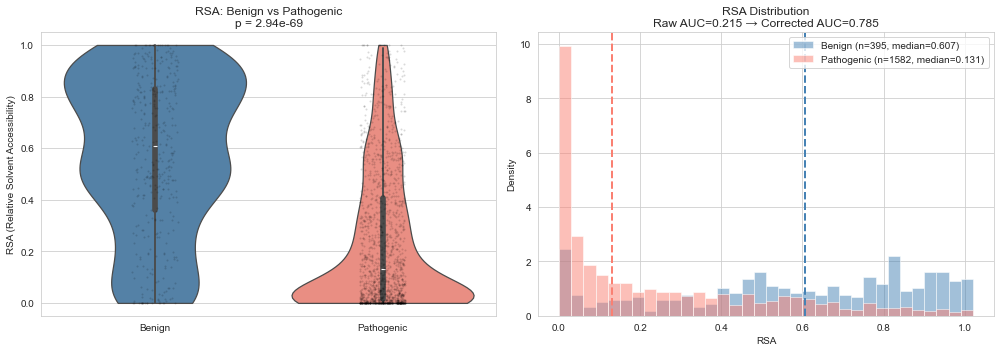

Pathogenic median RSA: 0.131 (more buried)
Benign median RSA:     0.607 (more exposed)
Raw AUC: 0.215 (< 0.5 means Pathogenic has LOWER values)
Corrected AUC: 0.785

→ The AUC of 0.24 is correct but means Pathogenic < Benign.
  Flip it: 1 - 0.24 = 0.76 = good separation in the expected direction.


In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

df_pb = df[df['clinvar_clinical_significance_unified'].isin(['Pathogenic', 'Benign'])].copy()
df_pb['rsa'] = pd.to_numeric(df_pb['rsa'], errors='coerce')

group_p = df_pb[df_pb['clinvar_clinical_significance_unified'] == 'Pathogenic']['rsa'].dropna()
group_b = df_pb[df_pb['clinvar_clinical_significance_unified'] == 'Benign']['rsa'].dropna()

stat, pval = mannwhitneyu(group_p, group_b, alternative='two-sided')
raw_auc = stat / (len(group_p) * len(group_b))
corrected_auc = max(raw_auc, 1 - raw_auc)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Violin plot
sns.violinplot(
    x='clinvar_clinical_significance_unified', y='rsa', data=df_pb,
    order=['Benign', 'Pathogenic'], palette={'Benign': 'steelblue', 'Pathogenic': 'salmon'},
    ax=axes[0], cut=0
)
sns.stripplot(
    x='clinvar_clinical_significance_unified', y='rsa', data=df_pb,
    order=['Benign', 'Pathogenic'], color='black', alpha=0.15, size=2, jitter=True,
    ax=axes[0]
)
axes[0].set_title(f'RSA: Benign vs Pathogenic\np = {pval:.2e}')
axes[0].set_xlabel('')
axes[0].set_ylabel('RSA (Relative Solvent Accessibility)')

# Histogram overlay
bins_rsa = np.arange(0, 1.05, 0.03)
axes[1].hist(group_b, bins=bins_rsa, alpha=0.5, density=True, label=f'Benign (n={len(group_b)}, median={group_b.median():.3f})', color='steelblue')
axes[1].hist(group_p, bins=bins_rsa, alpha=0.5, density=True, label=f'Pathogenic (n={len(group_p)}, median={group_p.median():.3f})', color='salmon')
axes[1].axvline(group_b.median(), color='steelblue', linestyle='--', linewidth=2)
axes[1].axvline(group_p.median(), color='salmon', linestyle='--', linewidth=2)
axes[1].set_xlabel('RSA')
axes[1].set_ylabel('Density')
axes[1].set_title(f'RSA Distribution\nRaw AUC={raw_auc:.3f} → Corrected AUC={corrected_auc:.3f}')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Pathogenic median RSA: {group_p.median():.3f} (more buried)")
print(f"Benign median RSA:     {group_b.median():.3f} (more exposed)")
print(f"Raw AUC: {raw_auc:.3f} (< 0.5 means Pathogenic has LOWER values)")
print(f"Corrected AUC: {corrected_auc:.3f}")
print(f"\n→ The AUC of 0.24 is correct but means Pathogenic < Benign.")
print(f"  Flip it: 1 - 0.24 = 0.76 = good separation in the expected direction.")

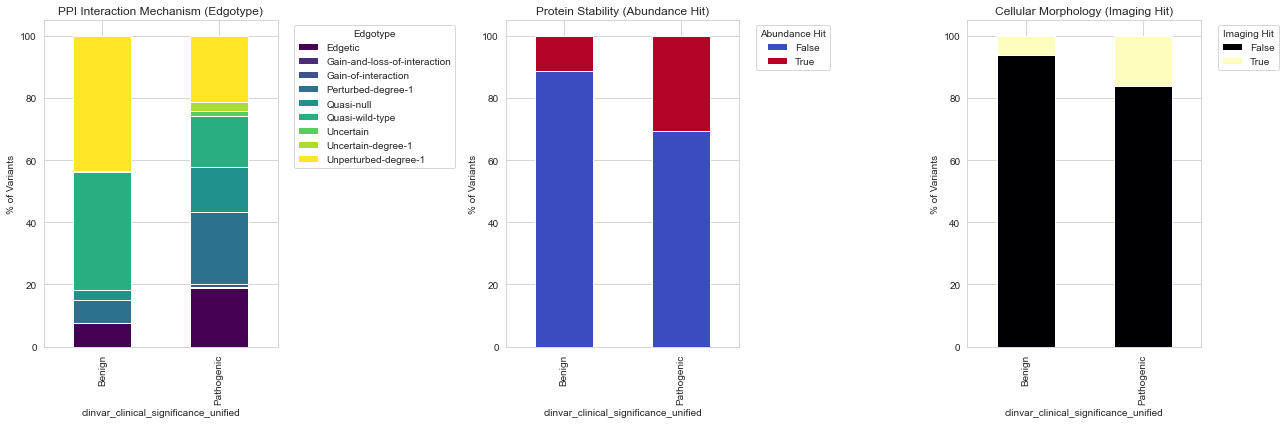

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_2160/2237032681.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='clinvar_clinical_significance_unified', y=col, data=df_pb, ax=axes2[i], palette="Set2", cut=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_2160/2237032681.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='clinvar_clinical_significance_unified', y=col, data=df_pb, ax=axes2[i], palette="Set2", cut=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_2160/2237032681.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=Fals

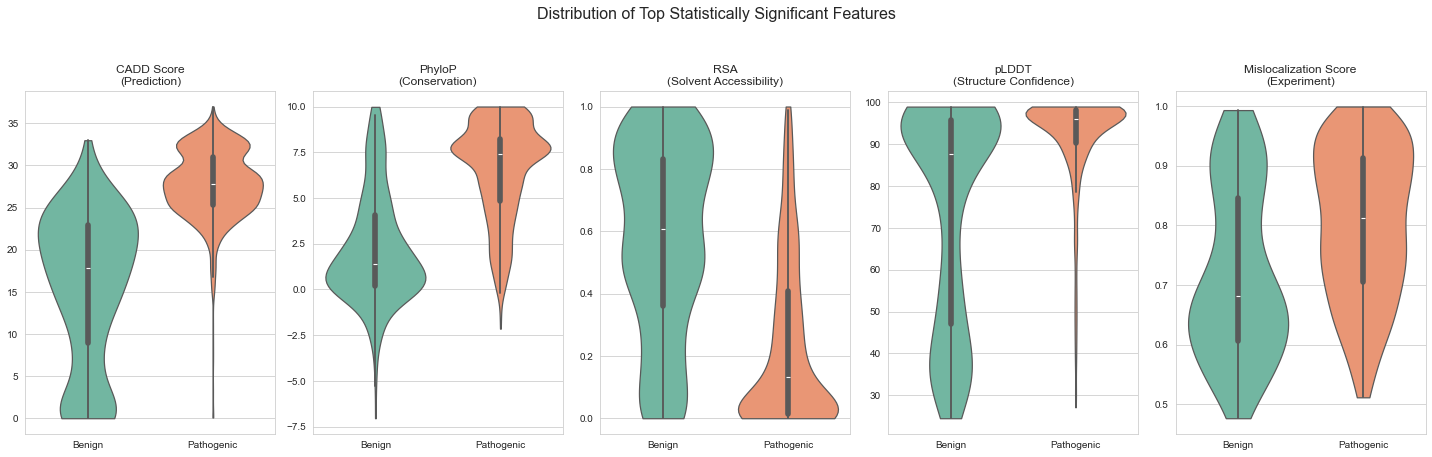

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_2160/2237032681.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='clinvar_clinical_significance_unified', y='dualipa_score', data=df_pb, ax=axes3[0], palette="coolwarm")
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_2160/2237032681.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='clinvar_clinical_significance_unified', y='img_misloc_score', data=df_pb, ax=axes3[1], palette="magma")
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_2160/2237032681.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set 

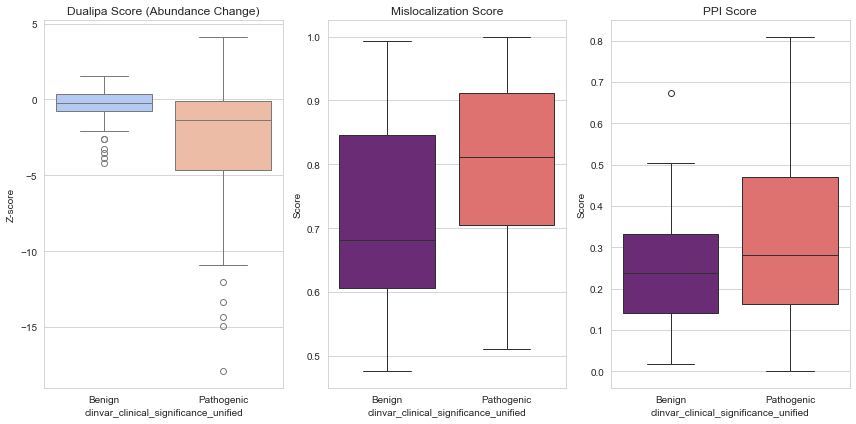

In [11]:

# ==========================================
# 3. Visualization
# ==========================================
sns.set_style("whitegrid")

# --- Figure 1: The Three Experimental Assays (Categorical) ---
fig1, axes1 = plt.subplots(1, 3, figsize=(18, 6))

# PPI (Edgotype)
ct_ppi = pd.crosstab(df_pb['clinvar_clinical_significance_unified'], df_pb['Edgotype_class'], normalize='index') * 100
ct_ppi.plot(kind='bar', stacked=True, ax=axes1[0], colormap='viridis')
axes1[0].set_title('PPI Interaction Mechanism (Edgotype)')
axes1[0].set_ylabel('% of Variants')
axes1[0].legend(title='Edgotype', bbox_to_anchor=(1.05, 1), loc='upper left')

# Abundance (Stability)
ct_abun = pd.crosstab(df_pb['clinvar_clinical_significance_unified'], df_pb['abundance_hit_unified'], normalize='index') * 100
ct_abun.plot(kind='bar', stacked=True, ax=axes1[1], colormap='coolwarm')
axes1[1].set_title('Protein Stability (Abundance Hit)')
axes1[1].set_ylabel('% of Variants')
axes1[1].legend(title='Abundance Hit', bbox_to_anchor=(1.05, 1), loc='upper left')

# Imaging (Localization)
ct_img = pd.crosstab(df_pb['clinvar_clinical_significance_unified'], df_pb['imaging_hit_unified'], normalize='index') * 100
ct_img.plot(kind='bar', stacked=True, ax=axes1[2], colormap='magma')
axes1[2].set_title('Cellular Morphology (Imaging Hit)')
axes1[2].set_ylabel('% of Variants')
axes1[2].legend(title='Imaging Hit', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# --- Figure 2: Top Relevant Annotations (Violin Plots) ---
# Selected based on the systematic scan results
selected_features = ['CADD_phred', 'phyloP100way_vertebrate', 'rsa', 'plddt', 'img_misloc_score']
titles = {
    'CADD_phred': 'CADD Score\n(Prediction)',
    'phyloP100way_vertebrate': 'PhyloP\n(Conservation)',
    'rsa': 'RSA\n(Solvent Accessibility)',
    'plddt': 'pLDDT\n(Structure Confidence)',
    'img_misloc_score': 'Mislocalization Score\n(Experiment)'
}

fig2, axes2 = plt.subplots(1, 5, figsize=(20, 6))

for i, col in enumerate(selected_features):
    # Use 'cut=0' to truncate violin at data range
    sns.violinplot(x='clinvar_clinical_significance_unified', y=col, data=df_pb, ax=axes2[i], palette="Set2", cut=0)
    axes2[i].set_title(titles.get(col, col))
    axes2[i].set_xlabel('')
    axes2[i].set_ylabel('')

plt.suptitle('Distribution of Top Statistically Significant Features', y=1.05, fontsize=16)
plt.tight_layout()
plt.show()

# --- Figure 3: Experimental Continuous Scores ---
fig3, axes3 = plt.subplots(1, 3, figsize=(12, 6))

# Dualipa Score (Continuous Abundance)
sns.boxplot(x='clinvar_clinical_significance_unified', y='dualipa_score', data=df_pb, ax=axes3[0], palette="coolwarm")
axes3[0].set_title('Dualipa Score (Abundance Change)')
axes3[0].set_ylabel('Z-score')

# Mislocalization Score (Continuous Imaging)
sns.boxplot(x='clinvar_clinical_significance_unified', y='img_misloc_score', data=df_pb, ax=axes3[1], palette="magma")
axes3[1].set_title('Mislocalization Score')
axes3[1].set_ylabel('Score')

# ppi_score (Continuous PPI)
sns.boxplot(x='clinvar_clinical_significance_unified', y='ppi_score', data=df_pb, ax=axes3[2], palette="magma")
axes3[2].set_title('PPI Score')
axes3[2].set_ylabel('Score')

plt.tight_layout()
plt.show()

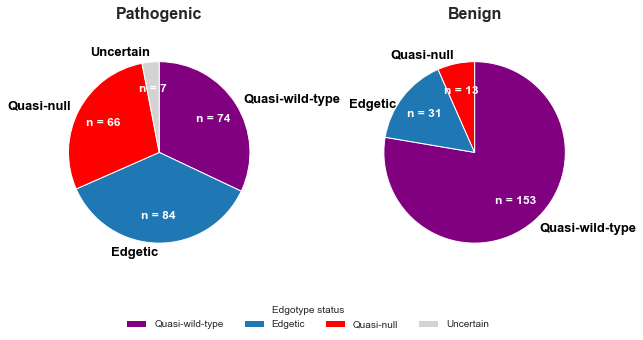

In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Filter for Pathogenic and Benign only
df_pb = df[df['clinvar_clinical_significance_unified'].isin(['Pathogenic', 'Benign'])].copy()

# Define edgotype order and colors
edgotype_order = ['Quasi-wild-type', 'Edgetic', 'Quasi-null', 'Uncertain']
edgotype_colors = ['purple', 'C0', 'red', 'lightgrey']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
fig.subplots_adjust(bottom=0.25, wspace=0.3)

for cat, ax in zip(['Pathogenic', 'Benign'], axs):
    vc = (df_pb.loc[df_pb['clinvar_clinical_significance_unified'] == cat, 'Edgotype_class']
          .value_counts(dropna=True)
          .reindex(edgotype_order)
          .fillna(0))
    
    # Skip categories with 0 count to avoid empty wedges
    vc_plot = vc[vc > 0]
    colors_plot = [edgotype_colors[edgotype_order.index(label)] for label in vc_plot.index]
    
    wedges, texts, autotexts = ax.pie(
        vc_plot,
        labels=vc_plot.index,
        autopct=lambda x: f"n = {x / 100 * vc_plot.sum():.0f}" if x > 0 else '',
        startangle=90,
        counterclock=False,
        colors=colors_plot,
        labeldistance=1.1,
        textprops={'color': 'black', 'weight': 'bold', 'fontsize': 13},
        pctdistance=0.7,
    )
    ax.set_title(cat, fontsize=16, weight='bold', pad=20)

    for autotext in autotexts:
        autotext.set_fontsize(12)
        autotext.set_weight('bold')
        autotext.set_color('white')
    
    # Move "Edgetic" label lower on the Benign pie if needed
    if cat == "Benign":
        for t in texts:
            if t.get_text() == "Edgetic":
                x, y = t.get_position()
                t.set_position((x, y - 0.15))

legend_elements = [
    Patch(facecolor='purple', label='Quasi-wild-type'),
    Patch(facecolor='C0', label='Edgetic'),
    Patch(facecolor='red', label='Quasi-null'),
    Patch(facecolor='lightgrey', label='Uncertain'),
]

fig.legend(
    handles=legend_elements,
    title="Edgotype status",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.05),
    ncol=4,
    frameon=False
)

plt.show()

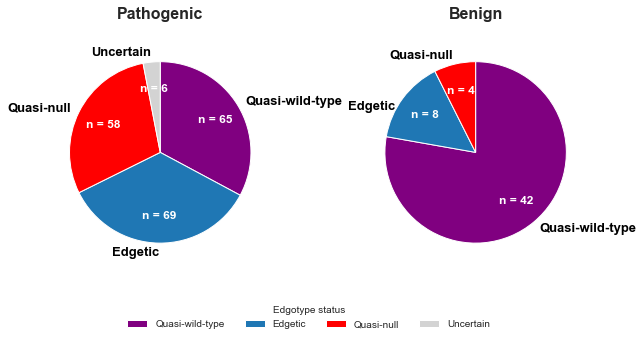

In [29]:
# No Fragoza variants

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Filter for Pathogenic and Benign only
df_pb = df[df['clinvar_clinical_significance_unified'].isin(['Pathogenic', 'Benign'])].copy()

df_pb = df_pb[~df_pb['Source_Simple'].str.contains('Fragoza')].copy()

# Define edgotype order and colors
edgotype_order = ['Quasi-wild-type', 'Edgetic', 'Quasi-null', 'Uncertain']
edgotype_colors = ['purple', 'C0', 'red', 'lightgrey']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
fig.subplots_adjust(bottom=0.25, wspace=0.3)

for cat, ax in zip(['Pathogenic', 'Benign'], axs):
    vc = (df_pb.loc[df_pb['clinvar_clinical_significance_unified'] == cat, 'Edgotype_class']
          .value_counts(dropna=True)
          .reindex(edgotype_order)
          .fillna(0))
    
    # Skip categories with 0 count to avoid empty wedges
    vc_plot = vc[vc > 0]
    colors_plot = [edgotype_colors[edgotype_order.index(label)] for label in vc_plot.index]
    
    wedges, texts, autotexts = ax.pie(
        vc_plot,
        labels=vc_plot.index,
        autopct=lambda x: f"n = {x / 100 * vc_plot.sum():.0f}" if x > 0 else '',
        startangle=90,
        counterclock=False,
        colors=colors_plot,
        labeldistance=1.1,
        textprops={'color': 'black', 'weight': 'bold', 'fontsize': 13},
        pctdistance=0.7,
    )
    ax.set_title(cat, fontsize=16, weight='bold', pad=20)

    for autotext in autotexts:
        autotext.set_fontsize(12)
        autotext.set_weight('bold')
        autotext.set_color('white')
    
    # Move "Edgetic" label lower on the Benign pie if needed
    if cat == "Benign":
        for t in texts:
            if t.get_text() == "Edgetic":
                x, y = t.get_position()
                t.set_position((x, y - 0.15))

legend_elements = [
    Patch(facecolor='purple', label='Quasi-wild-type'),
    Patch(facecolor='C0', label='Edgetic'),
    Patch(facecolor='red', label='Quasi-null'),
    Patch(facecolor='lightgrey', label='Uncertain'),
]

fig.legend(
    handles=legend_elements,
    title="Edgotype status",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.05),
    ncol=4,
    frameon=False
)

plt.show()

Benign variants:     668
Pathogenic variants: 1780

BENIGN OUTLIER IDENTIFICATION (threshold = pathogenic median)

CADD (Deleteriousness) (CADD_phred):
  Benign median: 17.855 | Pathogenic median: 27.800
  Outliers (≥ 27.800): 16/406 (3.9%)
  Strict outliers (≥ 31.000): 5

REVEL (Pathogenicity) (REVEL_score):
  Benign median: 0.194 | Pathogenic median: 0.873
  Outliers (≥ 0.873): 3/343 (0.9%)
  Strict outliers (≥ 0.938): 0

AlphaMissense (Pathogenicity) (am_pathogenicity):
  Benign median: 0.099 | Pathogenic median: 0.936
  Outliers (≥ 0.936): 5/400 (1.2%)
  Strict outliers (≥ 0.990): 0

PhyloP (Conservation) (phyloP100way_vertebrate):
  Benign median: 1.387 | Pathogenic median: 7.411
  Outliers (≥ 7.411): 39/406 (9.6%)
  Strict outliers (≥ 8.232): 18

RSA (Solvent Accessibility) (rsa):
  Benign median: 0.607 | Pathogenic median: 0.131
  Outliers (≤ 0.131): 49/395 (12.4%)
  Strict outliers (≤ 0.015): 24

pLDDT (Structure Confidence) (plddt):
  Benign median: 87.540 | Pathogenic median:

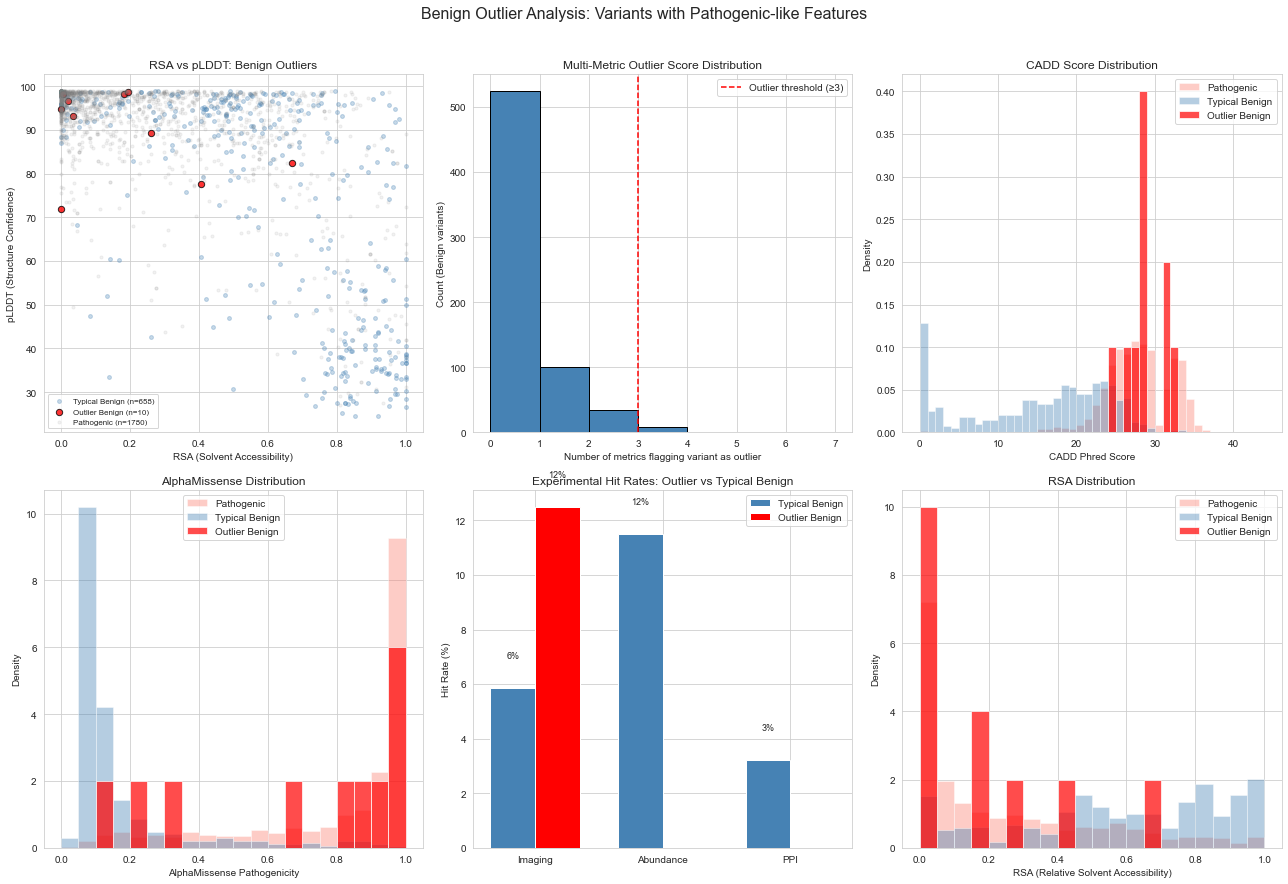

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import percentileofscore

# ==========================================
# 1. SETUP: Define metrics and their "pathogenic direction"
# ==========================================

# Metrics where Benign outliers would look pathogenic
# sign: +1 means higher = more pathogenic, -1 means lower = more pathogenic
metrics = {
    'CADD_phred':                {'sign': +1, 'label': 'CADD (Deleteriousness)'},
    'REVEL_score':               {'sign': +1, 'label': 'REVEL (Pathogenicity)'},
    'am_pathogenicity':          {'sign': +1, 'label': 'AlphaMissense (Pathogenicity)'},
    'phyloP100way_vertebrate':   {'sign': +1, 'label': 'PhyloP (Conservation)'},
    'rsa':                       {'sign': -1, 'label': 'RSA (Solvent Accessibility)'},    # low RSA = buried = more damaging
    'plddt':                     {'sign': +1, 'label': 'pLDDT (Structure Confidence)'},   # high pLDDT = structured = mutations more impactful
    # 'img_misloc_score':          {'sign': +1, 'label': 'Mislocalization Score'},
    # 'dualipa_score':             {'sign': -1, 'label': 'DualIPA (Abundance Change)'},     # negative = less protein
    # 'ppi_score':                 {'sign': -1, 'label': 'PPI Score'},                      # negative = less interaction
}

# Experimental evidence columns
exp_cols = {
    'Edgotype_class': 'PPI Edgotype',
    'imaging_hit_unified': 'Imaging Hit',
    'abundance_hit_unified': 'Abundance Hit',
    'ppi_hit': 'PPI Hit (1pct)',
    'dualipa_hit': 'DualIPA Hit (1pct)',
    'imaging_hit': 'Imaging Hit (1pct)',
}

# Ensure numeric
for col in metrics:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df_benign = df[df['clinvar_clinical_significance_unified'] == 'Benign'].copy()
df_pathogenic = df[df['clinvar_clinical_significance_unified'] == 'Pathogenic'].copy()

print(f"Benign variants:     {len(df_benign)}")
print(f"Pathogenic variants: {len(df_pathogenic)}")

# ==========================================
# 2. IDENTIFY BENIGN OUTLIERS per metric
# ==========================================

# A Benign is an "outlier" if its metric falls within the pathogenic distribution
# Threshold: beyond the pathogenic median (i.e., looks more pathogenic than half of pathogenics)

outlier_flags = pd.DataFrame(index=df_benign.index)
outlier_summary = []

print("\n" + "=" * 80)
print("BENIGN OUTLIER IDENTIFICATION (threshold = pathogenic median)")
print("=" * 80)

for col, info in metrics.items():
    path_vals = df_pathogenic[col].dropna()
    ben_vals = df_benign[col].dropna()
    
    if len(path_vals) < 10 or len(ben_vals) < 10:
        print(f"\n⚠️  {info['label']} ({col}): insufficient data (P={len(path_vals)}, B={len(ben_vals)})")
        continue
    
    path_median = path_vals.median()
    path_q75 = path_vals.quantile(0.75)
    path_q25 = path_vals.quantile(0.25)
    ben_median = ben_vals.median()
    
    if info['sign'] == +1:
        # Higher = more pathogenic → Benign outliers have values ABOVE pathogenic median
        threshold = path_median
        strict_threshold = path_q75
        outlier_mask = df_benign[col] >= threshold
        strict_mask = df_benign[col] >= strict_threshold
        direction = '≥'
    else:
        # Lower = more pathogenic → Benign outliers have values BELOW pathogenic median
        threshold = path_median
        strict_threshold = path_q25
        outlier_mask = df_benign[col] <= threshold
        strict_mask = df_benign[col] <= strict_threshold
        direction = '≤'
    
    n_outliers = outlier_mask.sum()
    n_strict = strict_mask.sum()
    n_with_data = df_benign[col].notna().sum()
    
    outlier_flags[f'outlier_{col}'] = outlier_mask
    outlier_flags[f'strict_outlier_{col}'] = strict_mask
    
    outlier_summary.append({
        'metric': col,
        'label': info['label'],
        'benign_median': ben_median,
        'pathogenic_median': path_median,
        'threshold': threshold,
        'direction': direction,
        'n_benign_with_data': n_with_data,
        'n_outliers': n_outliers,
        'pct_outliers': 100 * n_outliers / n_with_data if n_with_data > 0 else 0,
        'n_strict_outliers': n_strict,
    })
    
    print(f"\n{info['label']} ({col}):")
    print(f"  Benign median: {ben_median:.3f} | Pathogenic median: {path_median:.3f}")
    print(f"  Outliers ({direction} {threshold:.3f}): {n_outliers}/{n_with_data} ({100*n_outliers/n_with_data:.1f}%)")
    print(f"  Strict outliers ({direction} {strict_threshold:.3f}): {n_strict}")

summary_df = pd.DataFrame(outlier_summary)

# ==========================================
# 3. MULTI-METRIC OUTLIER SCORE
# ==========================================

# Count how many metrics flag each Benign variant as an outlier
outlier_cols = [c for c in outlier_flags.columns if c.startswith('outlier_')]
strict_cols = [c for c in outlier_flags.columns if c.startswith('strict_outlier_')]

df_benign['n_outlier_metrics'] = outlier_flags[outlier_cols].sum(axis=1)
df_benign['n_strict_outlier_metrics'] = outlier_flags[strict_cols].sum(axis=1)
df_benign['n_metrics_available'] = outlier_flags[outlier_cols].notna().sum(axis=1)
df_benign['outlier_fraction'] = df_benign['n_outlier_metrics'] / df_benign['n_metrics_available']

print("\n" + "=" * 80)
print("MULTI-METRIC OUTLIER SCORE (how many metrics flag each Benign as outlier)")
print("=" * 80)
print(f"\nDistribution of outlier metric count:")
print(df_benign['n_outlier_metrics'].value_counts().sort_index())

# ==========================================
# 4. TOP OUTLIER BENIGN VARIANTS + EXPERIMENTAL EVIDENCE
# ==========================================

# Focus on Benigns flagged by ≥3 metrics
n_threshold = 3
top_outliers = df_benign[df_benign['n_outlier_metrics'] >= n_threshold].copy()
top_outliers = top_outliers.sort_values('n_outlier_metrics', ascending=False)

print(f"\n{'=' * 80}")
print(f"TOP BENIGN OUTLIERS (flagged by ≥{n_threshold} metrics): {len(top_outliers)}")
print(f"{'=' * 80}")

# Build display table
display_cols = ['gene_variant', 'n_outlier_metrics', 'n_metrics_available']
display_cols += [col for col in exp_cols if col in df.columns]
display_cols += list(metrics.keys())
display_cols += ['Source_Simple']
display_cols = [c for c in display_cols if c in top_outliers.columns]

print(f"\n--- Experimental evidence for top outlier Benigns ---")
for _, row in top_outliers.head(30).iterrows():
    print(f"\n{'─' * 60}")
    print(f"  {row['gene_variant']}  (outlier in {int(row['n_outlier_metrics'])}/{int(row['n_metrics_available'])} metrics)")
    print(f"  Source: {row.get('Source_Simple', 'N/A')}")
    
    # Show which metrics flagged it
    flagged = []
    for col, info in metrics.items():
        flag_col = f'outlier_{col}'
        if flag_col in outlier_flags.columns:
            val = row.get(col, np.nan)
            if pd.notna(val) and outlier_flags.at[row.name, flag_col]:
                flagged.append(f"    ⚠️  {info['label']}: {val:.3f}")
    print("  Flagged metrics:")
    print('\n'.join(flagged))
    
    # Show experimental evidence
    print("  Experimental evidence:")
    has_evidence = False
    for col, label in exp_cols.items():
        if col in top_outliers.columns and pd.notna(row.get(col)):
            print(f"    🔬 {label}: {row[col]}")
            has_evidence = True
    if not has_evidence:
        print("    (none)")

# ==========================================
# 5. ENRICHMENT: Do outlier Benigns have more experimental hits?
# ==========================================

print(f"\n{'=' * 80}")
print("ENRICHMENT: Experimental hit rates in outlier vs non-outlier Benigns")
print(f"{'=' * 80}")

df_benign['is_outlier'] = df_benign['n_outlier_metrics'] >= n_threshold

for col, label in exp_cols.items():
    if col not in df_benign.columns:
        continue
    
    if df_benign[col].dtype == 'object':
        # Categorical (e.g., Edgotype_class)
        for group_name, group_df in df_benign.groupby('is_outlier'):
            group_label = 'Outlier Benign' if group_name else 'Typical Benign'
            n_total = len(group_df)
            n_with_data = group_df[col].notna().sum()
            if n_with_data > 0:
                print(f"\n  {label} — {group_label} (n={n_total}, with data={n_with_data}):")
                print(f"    {group_df[col].value_counts(dropna=True).to_dict()}")
    else:
        # Boolean (imaging_hit, abundance_hit, etc.)
        for group_name, group_df in df_benign.groupby('is_outlier'):
            group_label = 'Outlier Benign' if group_name else 'Typical Benign'
            n_total = group_df[col].notna().sum()
            n_hit = (group_df[col] == True).sum()
            hit_rate = 100 * n_hit / n_total if n_total > 0 else 0
            print(f"  {label} — {group_label}: {n_hit}/{n_total} hits ({hit_rate:.1f}%)")

# ==========================================
# 6. VISUALIZATION
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# A: Scatter RSA vs pLDDT colored by outlier status
ax = axes[0, 0]
non_outlier = df_benign[~df_benign['is_outlier']]
outlier = df_benign[df_benign['is_outlier']]
ax.scatter(non_outlier['rsa'], non_outlier['plddt'], alpha=0.3, s=15, c='steelblue', label=f'Typical Benign (n={len(non_outlier)})')
ax.scatter(outlier['rsa'], outlier['plddt'], alpha=0.8, s=40, c='red', edgecolors='black', label=f'Outlier Benign (n={len(outlier)})')
ax.scatter(df_pathogenic['rsa'], df_pathogenic['plddt'], alpha=0.1, s=10, c='grey', label=f'Pathogenic (n={len(df_pathogenic)})')
ax.set_xlabel('RSA (Solvent Accessibility)')
ax.set_ylabel('pLDDT (Structure Confidence)')
ax.set_title('RSA vs pLDDT: Benign Outliers')
ax.legend(fontsize=8)

# B: Distribution of outlier metric count
ax = axes[0, 1]
df_benign['n_outlier_metrics'].hist(ax=ax, bins=range(0, len(metrics) + 2), color='steelblue', edgecolor='black')
ax.axvline(n_threshold, color='red', linestyle='--', label=f'Outlier threshold (≥{n_threshold})')
ax.set_xlabel('Number of metrics flagging variant as outlier')
ax.set_ylabel('Count (Benign variants)')
ax.set_title('Multi-Metric Outlier Score Distribution')
ax.legend()

# C: CADD distribution: Benign outliers vs typical vs Pathogenic
ax = axes[0, 2]
bins = np.arange(0, 45, 1)
ax.hist(df_pathogenic['CADD_phred'].dropna(), bins=bins, alpha=0.4, density=True, label='Pathogenic', color='salmon')
ax.hist(non_outlier['CADD_phred'].dropna(), bins=bins, alpha=0.4, density=True, label='Typical Benign', color='steelblue')
ax.hist(outlier['CADD_phred'].dropna(), bins=bins, alpha=0.7, density=True, label='Outlier Benign', color='red')
ax.set_xlabel('CADD Phred Score')
ax.set_ylabel('Density')
ax.set_title('CADD Score Distribution')
ax.legend()

# D: AlphaMissense distribution
ax = axes[1, 0]
bins_am = np.arange(0, 1.05, 0.05)
ax.hist(df_pathogenic['am_pathogenicity'].dropna(), bins=bins_am, alpha=0.4, density=True, label='Pathogenic', color='salmon')
ax.hist(non_outlier['am_pathogenicity'].dropna(), bins=bins_am, alpha=0.4, density=True, label='Typical Benign', color='steelblue')
ax.hist(outlier['am_pathogenicity'].dropna(), bins=bins_am, alpha=0.7, density=True, label='Outlier Benign', color='red')
ax.set_xlabel('AlphaMissense Pathogenicity')
ax.set_ylabel('Density')
ax.set_title('AlphaMissense Distribution')
ax.legend()

# E: Experimental hit rate comparison (bar chart)
ax = axes[1, 1]
hit_cols_bool = ['imaging_hit_unified', 'abundance_hit_unified', 'ppi_hit']
hit_labels = ['Imaging', 'Abundance', 'PPI']
x = np.arange(len(hit_cols_bool))
width = 0.35

rates_typical = []
rates_outlier = []
for col in hit_cols_bool:
    if col in df_benign.columns:
        typ = non_outlier[col].dropna()
        out = outlier[col].dropna()
        rates_typical.append(100 * typ.sum() / len(typ) if len(typ) > 0 else 0)
        rates_outlier.append(100 * out.sum() / len(out) if len(out) > 0 else 0)
    else:
        rates_typical.append(0)
        rates_outlier.append(0)

bars1 = ax.bar(x - width/2, rates_typical, width, label='Typical Benign', color='steelblue')
bars2 = ax.bar(x + width/2, rates_outlier, width, label='Outlier Benign', color='red')
ax.set_ylabel('Hit Rate (%)')
ax.set_title('Experimental Hit Rates: Outlier vs Typical Benign')
ax.set_xticks(x)
ax.set_xticklabels(hit_labels)
ax.legend()

# Add count labels on bars
for bar, rate in zip(bars1, rates_typical):
    if rate > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{rate:.0f}%', ha='center', va='bottom', fontsize=9)
for bar, rate in zip(bars2, rates_outlier):
    if rate > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{rate:.0f}%', ha='center', va='bottom', fontsize=9)

# F: RSA distribution
ax = axes[1, 2]
bins_rsa = np.arange(0, 1.05, 0.05)
ax.hist(df_pathogenic['rsa'].dropna(), bins=bins_rsa, alpha=0.4, density=True, label='Pathogenic', color='salmon')
ax.hist(non_outlier['rsa'].dropna(), bins=bins_rsa, alpha=0.4, density=True, label='Typical Benign', color='steelblue')
ax.hist(outlier['rsa'].dropna(), bins=bins_rsa, alpha=0.7, density=True, label='Outlier Benign', color='red')
ax.set_xlabel('RSA (Relative Solvent Accessibility)')
ax.set_ylabel('Density')
ax.set_title('RSA Distribution')
ax.legend()

plt.suptitle('Benign Outlier Analysis: Variants with Pathogenic-like Features', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ==========================================
# 7. EXPORT OUTLIER TABLE
# ==========================================

export_cols = ['gene_variant', 'gene_symbol', 'aa_change', 
               'clinvar_clinical_significance_unified', 
               'n_outlier_metrics', 'n_metrics_available', 'outlier_fraction',
               'Source_Simple']
export_cols += list(metrics.keys())
export_cols += [c for c in exp_cols if c in df_benign.columns]
export_cols = [c for c in export_cols if c in df_benign.columns]

# outlier_export = top_outliers[export_cols].sort_values('n_outlier_metrics', ascending=False)
# outlier_export.to_csv('../3_outputs/Benign_outliers_pathogenic_features.csv', index=False)
# print(f"\n✅ Exported {len(outlier_export)} outlier Benign variants to ../3_outputs/Benign_outliers_pathogenic_features.csv")

In [13]:
df[df.gene_variant == 'SOS2_Val869Ile']

,gene_variant,gene_symbol,aa_change,clinvar_clinical_significance_unified,clinvar_clinical_significance_source_unified,Edgotype_class,Edgotype_source,imaging_hit_unified,imaging_hit_unified_source,imaging_hit_discordant,...,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,am_pathogenicity
5120,SOS2_Val869Ile,SOS2,Val869Ile,Benign,1pct_allele_col,NaN,NaN,True,1pct,NaN,...,>90,<10,616559,autosomal dominant,GenCC,NaN,0.0,NOONAN SYNDROME 9,False,0.1295
